# Rain Prediction — Temporal features, on BOTH splits

Adds within-station **temporal/lagged** features (the highest-value untested lever per EXP-003's
noise-floor analysis) and evaluates them on **two protocols, deliberately**:

- **Chronological** — le split du pipeline (`train < 2016-01-01 <= test`), c'est-à-dire la vraie
  prévision à un jour.
- **Leave-stations-out** (20% of stations held out) — spatial generalization. (This is the split
  EXP-001/002 ran *by accident*; here it is intentional and labelled.)

Les features retardées sont construites sur **`weatherAUS_trend_grouped.csv`** — la sortie
pré-imputation de `3.preprocessing_trend_group.ipynb` — avec des décalages **strictement
arrière**, donc aucune valeur du futur et aucune valeur reconstruite par MICE ne remonte dans un
lag. Les features de base et le split viennent de `4_preprocessing_imputation.ipynb`
(`weatherAUS_{X,y}_{train,test}.csv`). Les deux frames partagent la clé unique `(Date, Location)`,
ce qui rend le recollement exact.

Outputs -> `TEMPORAL_result.txt`, figures `temporal_*`, modèles `joblib` dans `../../models/`.


## 1. Setup, imports, constants

In [2]:
import os, sys, warnings
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, GroupKFold, GroupShuffleSplit
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, precision_recall_curve, auc,
)
import xgboost as xgb
from xgboost import XGBClassifier
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')

def _gpu_available():
    try:
        d = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, d, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); CPU fallback.'); return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
SEARCH_N_JOBS = 1 if USE_GPU else -1
XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)
def make_xgb(**ov):
    p = dict(XGB_KW); p.update(ov); return XGBClassifier(**p)

# Frozen deployment-candidate config from EXP-2026-06-15-002 (scale_pos_weight set per split).
V2_PARAMS = dict(max_depth=6, min_child_weight=10, gamma=2.0, reg_lambda=20, reg_alpha=0.5,
                 learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_estimators=800)
print(f'xgboost {xgb.__version__} | device: {DEVICE}')

xgboost 3.4.0 | device: cuda


### Output setup

In [3]:
os.makedirs('figures', exist_ok=True)
_PATH = 'TEMPORAL_result.txt'
_FILE = open(_PATH, 'w', encoding='utf-8')
class _Tee:
    def __init__(self, *s): self._s = s
    def write(self, d):
        for s in self._s: s.write(d)
    def flush(self):
        for s in self._s: s.flush()
    def isatty(self): return False
_ORIG = sys.stdout; sys.stdout = _Tee(_ORIG, _FILE)
print('# Temporal features (both splits) — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
def log_section(t):
    print('\n' + '=' * 72 + '\n' + t + '\n' + '=' * 72)
def save_fig(name, fig=None):
    fig = fig or plt.gcf(); p = f'figures/{name}.png'
    fig.savefig(p, dpi=150, bbox_inches='tight'); print(f'  [saved {p}]')

# --- Sérialisation des modèles ---------------------------------------------
# Chaque étape du notebook est enregistrée dans <repo>/models sous forme d'un
# dict joblib : le modèle + les métadonnées nécessaires pour le rejouer.
MODEL_DIR = os.environ.get('WEATHER_MODEL_DIR', '../../models')
os.makedirs(MODEL_DIR, exist_ok=True)
NOTEBOOK = 'EXP-004_XGBoost_temporal'

def save_model(obj, name, **meta):
    """Sauvegarde `obj` dans MODEL_DIR/<name>.joblib avec ses métadonnées."""
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': obj,
                 'notebook': NOTEBOOK,
                 'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                 **meta}, path)
    print(f'  [saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)]')

# Temporal features (both splits) — numerical outputs
# Generated: 2026-08-11 12:54:29

2. Data loading (sorties du pipeline)
X_train (113506, 29) | X_test (25314, 29)
Train 2007-11-01 -> 2015-12-31 | Test 2016-01-01 -> 2017-06-25
Stations : 49 | pluie train 21.9574% / test 22.6950%
Pré-imputation : 138,820 lignes x 27 colonnes (292,371 NaN conservés)
<xml><var name="_dummy_ipython_val"  />
<var name="_dummy_special_var"  />
<var name="DATA_DIR" type="str" qualifier="builtins" value="../../data" />
<var name="DEVICE" type="str" qualifier="builtins" value="cuda" />
<var name="GroupKFold" type="ABCMeta" qualifier="abc" value="%3Cclass %27sklearn.model_selection._split.GroupKFold%27&gt;" isContainer="True" />
<var name="GroupShuffleSplit" type="ABCMeta" qualifier="abc" value="%3Cclass %27sklearn.model_selection._split.GroupShuffleSplit%27&gt;" isContainer="True" />
<var name="IN_COLAB" type="bool" qualifier="builtins" value="True" />
<var name="MODEL_DIR" type="str" qualifier="builtins" v

## 2. Chargement — frame pré-imputation (pour les lags) + matrices du pipeline

In [4]:
log_section('2. Data loading (sorties du pipeline)')

# Sorties du pipeline, dans <repo>/data :
#   3.preprocessing_trend_group.ipynb -> weatherAUS_trend_grouped.csv
#   4_preprocessing_imputation.ipynb  -> weatherAUS_MICE_cyclic.csv
#                                        weatherAUS_X_train.csv / weatherAUS_y_train.csv
#                                        weatherAUS_X_test.csv  / weatherAUS_y_test.csv
DATA_DIR = os.environ.get('WEATHER_DATA_DIR', '../../data')

# Matrices déjà splitées, encodées (LabelEncoder) et scalées (RobustScaler ajusté
# sur le train uniquement) par 4_preprocessing_imputation.ipynb.
X_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_train.csv')
X_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_test.csv')
y_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_train.csv').squeeze('columns').astype(int)
y_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_test.csv').squeeze('columns').astype(int)

# Index (Date, Location) aligné ligne à ligne sur X_train / X_test :
# weatherAUS_MICE_cyclic.csv est trié par Date et le pipeline y applique le même
# seuil TEST_CUTOFF, donc ses len(X_train) premières lignes SONT celles de X_train.
meta = pd.read_csv(f'{DATA_DIR}/weatherAUS_MICE_cyclic.csv',
                   usecols=['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm'], parse_dates=['Date'])
meta = meta[['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']]
assert len(meta) == len(X_train) + len(X_test), 'X_train/X_test ne recouvrent pas MICE_cyclic'
meta_train = meta.iloc[:len(X_train)].reset_index(drop=True)
meta_test  = meta.iloc[len(X_train):].reset_index(drop=True)
assert (meta_train['Date'] < TEST_CUTOFF).all(), 'lignes de train postérieures au seuil'
assert (meta_test['Date'] >= TEST_CUTOFF).all(), 'lignes de test antérieures au seuil'

print(f'X_train {X_train.shape} | X_test {X_test.shape}')
print(f'Train {meta_train["Date"].min().date()} -> {meta_train["Date"].max().date()} | '
      f'Test {meta_test["Date"].min().date()} -> {meta_test["Date"].max().date()}')
print(f'Stations : {meta["Location"].nunique()} | pluie train {y_train.mean():.4%} / test {y_test.mean():.4%}')

# Frame AVANT imputation (mêmes lignes, NaN d'origine conservés) : sert à
# reconstruire les features retardées / voisines sans réutiliser de valeur
# reconstruite par MICE.
pre = pd.read_csv(f'{DATA_DIR}/weatherAUS_trend_grouped.csv', parse_dates=['Date'])
assert len(pre) == len(meta), 'weatherAUS_trend_grouped.csv désaligné du pipeline'
print(f'Pré-imputation : {pre.shape[0]:,} lignes x {pre.shape[1]} colonnes '
      f'({pre.isna().sum().sum():,} NaN conservés)')

## 3. Base features (v2)

In [5]:
log_section('3. Base features (v2)')

# Features de tendance intra-journalière. Elles sont calculées sur les valeurs
# NON scalées de weatherAUS_MICE_cyclic.csv : une différence de colonnes déjà
# passées au RobustScaler (échelles distinctes) ne serait pas la même grandeur.
for X, m in ((X_train, meta_train), (X_test, meta_test)):
    X['Pressure_diff'] = (m['Pressure3pm'] - m['Pressure9am']).to_numpy()
    X['Temp_diff']     = (m['Temp3pm']     - m['Temp9am']).to_numpy()

# Le pipeline livre 29 colonnes. On retire les mêmes que l'étude LR pour que les
# expériences EXP-001..007 restent comparables entre elles :
DROP_COLS = [
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # labels encodés ; les sin/cos sont conservés
    'RainToday',                                # quasi-fuite (on donne déjà le reste de la journée)
    'Humidity9am',                              # on garde Humidity3pm (plus prédictive)
    'Month',                                    # redondant avec Date_sin / Date_cos
]
BASE_FEATURES = [c for c in X_train.columns if c not in DROP_COLS]

# Matrice complète dans l'ordre chronologique du pipeline : X_train puis X_test.
# Les blocs de features additionnels (temporel / spatial) viendront s'y coller.
X_all = pd.concat([X_train[BASE_FEATURES], X_test[BASE_FEATURES]], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
loc_all = meta['Location']
dates   = meta['Date']
N_TRAIN = len(X_train)

def align_to_pipeline(frame, cols):
    """Réaligne un bloc de features indexé par (Date, Location) sur l'ordre des
    lignes du pipeline. Les deux frames partagent la même clé unique, donc le
    réalignement est exact et ne peut pas dupliquer de ligne."""
    key = pd.MultiIndex.from_frame(frame[['Date', 'Location']])
    assert key.is_unique, 'clé (Date, Location) non unique dans le bloc de features'
    out = frame.set_axis(key)[cols].reindex(pd.MultiIndex.from_frame(meta[['Date', 'Location']]))
    return out.reset_index(drop=True)

print(f'BASE features: {len(BASE_FEATURES)} | X_all {X_all.shape}')

## 4. Temporal features from the PRE-imputation frame (strictly backward)

All features below use only days `<= t-1` (no same-day info, no future), built per `Location` on
**`weatherAUS_trend_grouped.csv`** — le frame *avant* MICE — so l'imputation par groupe de
tendance ne peut pas faire remonter une valeur reconstruite dans un lag. Resulting NaNs (first
days / originally-missing) are left for XGBoost to handle natively — we do **not** impute lags
(EXP-003 showed imputation adds no signal).


In [6]:
log_section('4. Temporal features (frame pré-imputation, décalages arrière)')

# Toutes les features ci-dessous n'utilisent que les jours <= t-1 (pas d'info du jour
# même, pas de futur), construites par `Location` sur weatherAUS_trend_grouped.csv,
# c'est-à-dire AVANT l'imputation MICE : aucune valeur reconstruite ne peut remonter
# dans un lag. Les NaN qui en résultent (premiers jours / manquants d'origine) sont
# laissés tels quels — XGBoost les gère nativement et EXP-003 a montré que les
# imputer n'apporte rien.
pre_s = pre.sort_values(['Location', 'Date']).copy()
g = pre_s.groupby('Location', sort=False)

LAG_COLS = ['Humidity3pm','Pressure3pm','Rainfall','Cloud3pm','Sunshine','Temp3pm','WindGustSpeed']
feat = pd.DataFrame({'Date': pre_s['Date'].values, 'Location': pre_s['Location'].values})
for c in LAG_COLS:
    feat[f'{c}_lag1'] = g[c].shift(1).values

# multi-day, all strictly past (>= t-1)
feat['Pressure_3d_chg']  = (g['Pressure3pm'].shift(1) - g['Pressure3pm'].shift(4)).values
feat['Humidity_3d_mean'] = g['Humidity3pm'].apply(lambda s: s.shift(1).rolling(3).mean()).values
feat['Rainfall_3d_sum']  = g['Rainfall'].apply(lambda s: s.shift(1).rolling(3).sum()).values

# yesterday's rain flag + days since last rain (computed on the lagged flag -> strictly past)
rt = pre_s['RainToday'].astype(int)          # booléen dans le frame du pipeline
rt_lag = rt.groupby(pre_s['Location'], sort=False).shift(1)
feat['RainToday_lag1'] = rt_lag.values
def _days_since(s):
    out = np.empty(len(s)); cnt = 9999.0
    for i, v in enumerate(s.to_numpy()):
        out[i] = cnt
        cnt = 0.0 if v == 1 else (cnt + 1 if cnt < 9999 else 9999)
    return out
feat['days_since_rain'] = (
    rt_lag.fillna(0).groupby(pre_s['Location'], sort=False).transform(lambda s: _days_since(s)).values)

TEMPORAL_FEATURES = [c for c in feat.columns if c not in ('Date', 'Location')]
X_all[TEMPORAL_FEATURES] = align_to_pipeline(feat, TEMPORAL_FEATURES)
nan_share = X_all[TEMPORAL_FEATURES].isna().mean().mean()
print(f'Temporal features: {len(TEMPORAL_FEATURES)} -> {TEMPORAL_FEATURES}')
print(f'Mean NaN share across temporal features: {nan_share:.1%} (left for XGBoost native handling)')

## 5. Two evaluation protocols

In [7]:
log_section('5. Splits: chronologique (pipeline) + leave-stations-out')

# Chronologique : on REPREND le split du pipeline tel quel (les N_TRAIN premières
# lignes de X_all sont exactement X_train). Plus aucun re-tri n'est effectué ici,
# donc le bug de EXP-003 — masque trié par date appliqué à des features restées
# dans l'ordre d'origine, groupées par Location — ne peut plus se produire.
chrono_train = np.zeros(len(X_all), dtype=bool)
chrono_train[:N_TRAIN] = True
assert dates[chrono_train].max() < dates[~chrono_train].min(), 'split non chronologique !'
print('Chronological (pipeline):')
print(f'  train {chrono_train.sum():,} ({dates[chrono_train].min().date()}..{dates[chrono_train].max().date()})')
print(f'  test  {(~chrono_train).sum():,} ({dates[~chrono_train].min().date()}..{dates[~chrono_train].max().date()})')

# Leave-stations-out (split spatial délibéré, indépendant du pipeline)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
sp_tr, sp_te = next(gss.split(X_all, y_all, groups=loc_all))
spatial_train = np.zeros(len(X_all), bool); spatial_train[sp_tr] = True
held = sorted(loc_all.iloc[sp_te].unique())
print(f'Leave-stations-out: {len(held)} held-out stations -> {held}')
print(f'  train {spatial_train.sum():,} | test {(~spatial_train).sum():,}')

SPLITS = {
    'chronological':      dict(train=chrono_train,  cv='time'),
    'leave-stations-out': dict(train=spatial_train, cv='group'),
}

ALL_FEATURES = BASE_FEATURES + TEMPORAL_FEATURES
FEATURE_SETS = {'base': BASE_FEATURES, 'base+temporal': ALL_FEATURES}
assert list(X_all.columns) == ALL_FEATURES

## 6. Helpers — PR-crossover threshold + per-config evaluation

In [8]:
def pr_crossover_threshold(params, Xtr, ytr, cv, groups, grid=np.arange(0.10, 0.81, 0.01)):
    recs = []
    for tr, va in cv.split(Xtr, ytr, groups):
        m = make_xgb(**params); m.fit(Xtr.iloc[tr], ytr.iloc[tr])
        recs.append((ytr.iloc[va].values, m.predict_proba(Xtr.iloc[va])[:, 1]))
    best_t, best_d = 0.5, 1e9
    for t in grid:
        P = np.mean([precision_score(y, p >= t, zero_division=0) for y, p in recs])
        R = np.mean([recall_score(y, p >= t) for y, p in recs])
        F = np.mean([f1_score(y, p >= t) for y, p in recs])
        d = abs(P - F) + abs(F - R)
        if d < best_d: best_t, best_d = float(t), d
    return round(best_t, 2)

def evaluate(fs_name, cols, split_name, train_mask, cv_kind):
    Xtr = X_all.loc[train_mask, cols].reset_index(drop=True)
    Xte = X_all.loc[~train_mask, cols].reset_index(drop=True)
    ytr = y_all[train_mask].reset_index(drop=True)
    yte = y_all[~train_mask].reset_index(drop=True)
    pr = float(ytr.mean()); params = dict(V2_PARAMS); params['scale_pos_weight'] = (1 - pr) / pr
    if cv_kind == 'time':
        cv, groups = TimeSeriesSplit(n_splits=5), None
    else:
        cv, groups = GroupKFold(n_splits=5), loc_all[train_mask].reset_index(drop=True)
    t = pr_crossover_threshold(params, Xtr, ytr, cv, groups)
    m = make_xgb(**params); m.fit(Xtr, ytr)
    proba = m.predict_proba(Xte)[:, 1]; pred = (proba >= t).astype(int)
    p, r, _ = precision_recall_curve(yte, proba)
    row = dict(split=split_name, features=fs_name, n_feat=len(cols), threshold=t,
               F1=round(f1_score(yte, pred), 4),
               precision=round(precision_score(yte, pred), 4),
               recall=round(recall_score(yte, pred), 4),
               ROC_AUC=round(roc_auc_score(yte, proba), 4),
               PR_AUC=round(auc(r, p), 4))
    return m, row, proba, yte

## 7. Run all 4 configurations (2 splits x 2 feature sets)

In [9]:
log_section('7. Results — 2 splits x 2 feature sets')
results, store = [], {}
for sp_name, sp in SPLITS.items():
    for fs_name, cols in FEATURE_SETS.items():
        m, row, proba, yte = evaluate(fs_name, cols, sp_name, sp['train'], sp['cv'])
        results.append(row); store[(sp_name, fs_name)] = (m, proba, yte)
        print(f"  {sp_name:20s} {fs_name:14s} -> F1 {row['F1']:.4f}  ROC {row['ROC_AUC']:.4f}  PR {row['PR_AUC']:.4f}")
res = pd.DataFrame(results)
print('\nMaster table:')
print(res.to_string(index=False))

for (sp_name, fs_name), (m, _proba, _yte) in store.items():
    row = next(r for r in results if r['split'] == sp_name and r['features'] == fs_name)
    save_model(m, f"EXP-004_{sp_name.replace('-', '_')}__{fs_name.replace('+', '_')}",
               features=FEATURE_SETS[fs_name], split=sp_name, stage=f'{fs_name} / {sp_name}',
               params=V2_PARAMS, threshold=row['threshold'], metrics=row)

## 8. ROC / PR curves per split

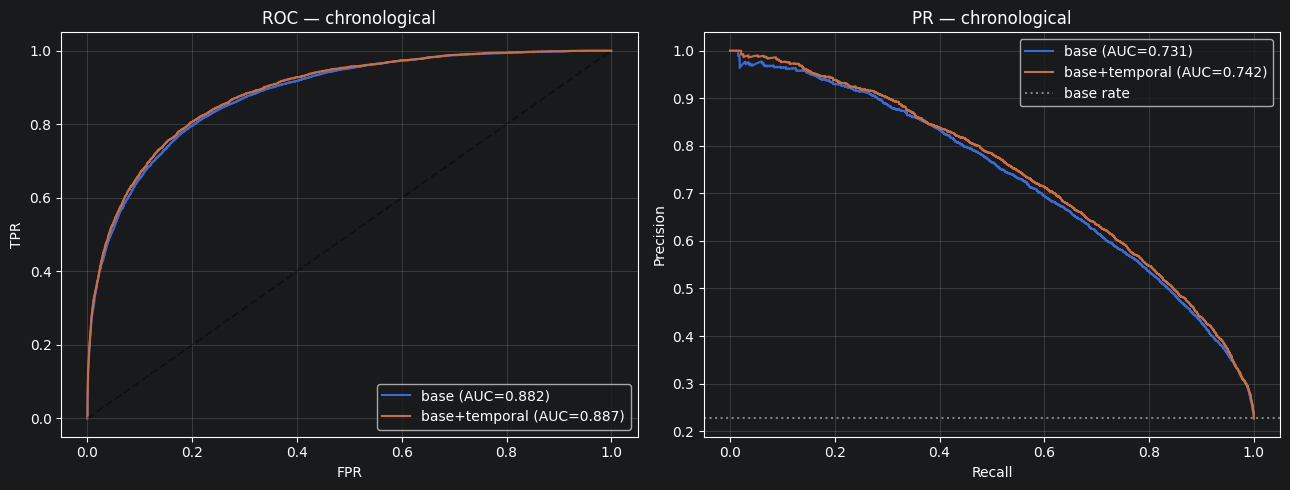

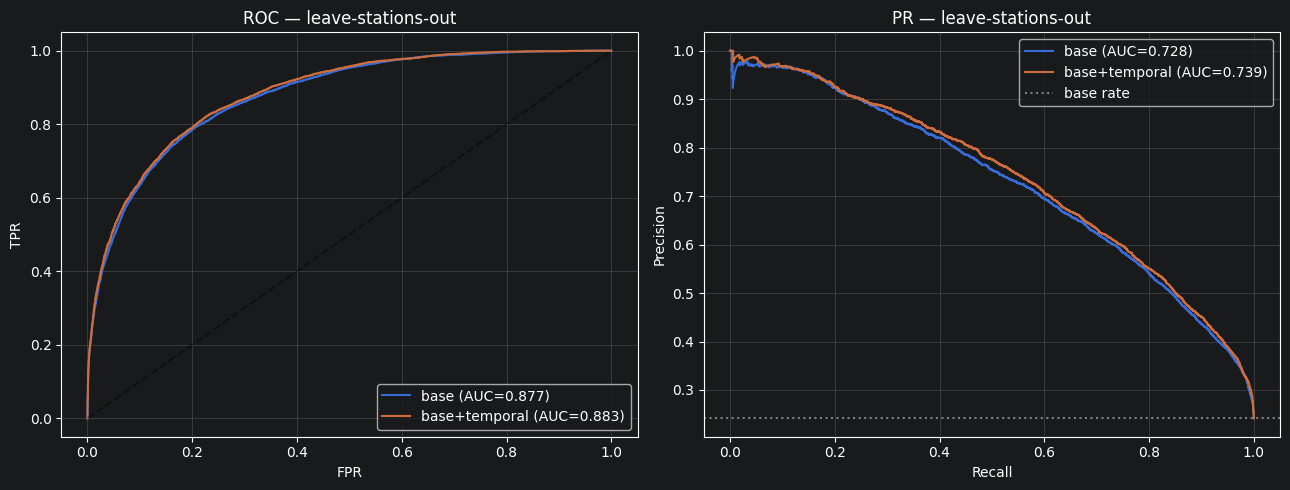

In [10]:
for sp_name in SPLITS:
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for fs_name in FEATURE_SETS:
        _, proba, yte = store[(sp_name, fs_name)]
        fpr, tpr, _ = roc_curve(yte, proba)
        ax[0].plot(fpr, tpr, label=f'{fs_name} (AUC={roc_auc_score(yte, proba):.3f})')
        p, r, _ = precision_recall_curve(yte, proba)
        ax[1].plot(r, p, label=f'{fs_name} (AUC={auc(r, p):.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4); ax[0].set_title(f'ROC — {sp_name}')
    ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(loc='lower right'); ax[0].grid(alpha=0.3)
    ax[1].axhline(float(store[(sp_name, "base")][2].mean()), color='gray', ls=':', label='base rate')
    ax[1].set_title(f'PR — {sp_name}'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
    ax[1].legend(loc='upper right'); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    save_fig(f'temporal_roc_pr_{sp_name.replace("-", "_")}', fig); plt.show()

## 9. Do temporal features matter? (gain importance, chronological model)

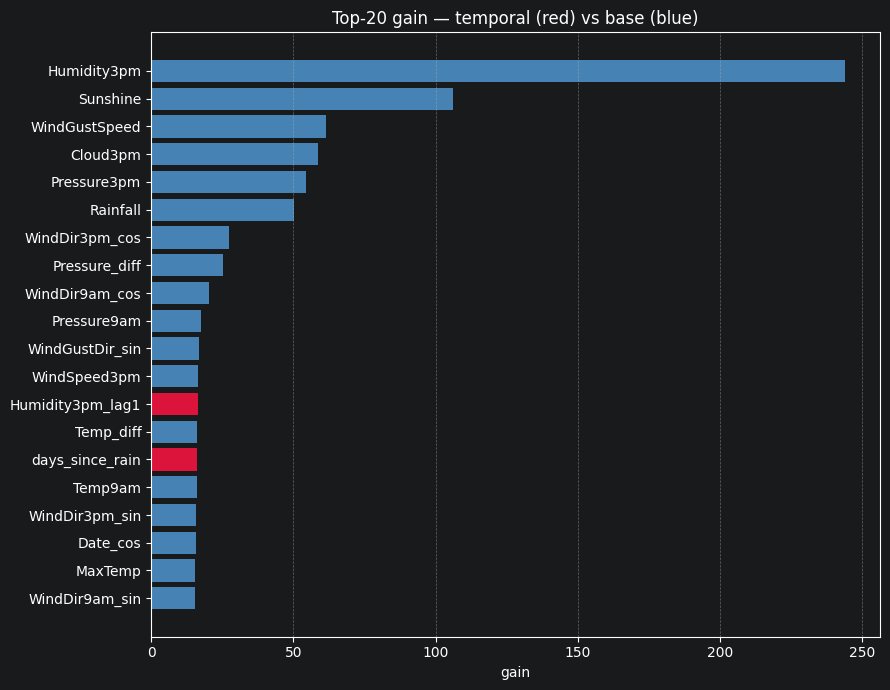

In [11]:
log_section('9. Temporal-feature importance (chronological, base+temporal)')
m_aug = store[('chronological', 'base+temporal')][0]
gain = m_aug.get_booster().get_score(importance_type='gain')
imp = pd.DataFrame([(k, gain.get(k, 0.0)) for k in ALL_FEATURES],
                   columns=['feature', 'gain']).sort_values('gain', ascending=False).reset_index(drop=True)
imp['is_temporal'] = imp['feature'].isin(TEMPORAL_FEATURES)
print('Top 20 by gain (* = temporal):')
for _, r in imp.head(20).iterrows():
    print(f"  {'*' if r.is_temporal else ' '} {r.feature:22s} {r.gain:8.2f}")
n_top10 = int(imp.head(10)['is_temporal'].sum())
print(f'\nTemporal features in top 10: {n_top10}/10')

fig, ax = plt.subplots(figsize=(9, 7))
top = imp.head(20)
ax.barh(top['feature'][::-1], top['gain'][::-1],
        color=['crimson' if t else 'steelblue' for t in top['is_temporal']][::-1])
ax.set_xlabel('gain'); ax.set_title('Top-20 gain — temporal (red) vs base (blue)')
ax.grid(axis='x', ls='--', alpha=0.5); plt.tight_layout()
save_fig('temporal_feature_importance', fig); plt.show()

## 10. Verdict

In [12]:
log_section('10. Verdict — did temporal features help?')
def delta(sp):
    b = res[(res.split == sp) & (res.features == 'base')].iloc[0]
    t = res[(res.split == sp) & (res.features == 'base+temporal')].iloc[0]
    return t.F1 - b.F1, t.ROC_AUC - b.ROC_AUC, t.PR_AUC - b.PR_AUC
for sp in SPLITS:
    dF1, dROC, dPR = delta(sp)
    print(f'  {sp:20s}  dF1 {dF1:+.4f} | dROC {dROC:+.4f} | dPR {dPR:+.4f}')
dF1_c, dROC_c, dPR_c = delta('chronological')
print()
print('Reference (prior, spatial-split-by-accident): v2 ROC 0.899 / PR 0.733 / F1 0.66')
print('  -> compare to the corrected `chronological / base` row above for the TRUE re-baseline.')
if dROC_c >= 0.005 or dPR_c >= 0.005 or dF1_c >= 0.005:
    print('\nVERDICT: temporal features ADD signal on the forecasting task. Keep them; iterate on richer lags.')
else:
    print('\nVERDICT: temporal features do not materially help even on the chronological split.')
    print('  -> the next lever is spatial context or a reframed target, not more same-station history.')

## Finalization

In [13]:
log_section('Finalization')
print(f'Results file: {_PATH}')
figs = sorted(f for f in os.listdir('figures') if f.startswith('temporal_'))
for f in figs: print(f'  figures/{f}')
models = sorted(f for f in os.listdir(MODEL_DIR) if f.startswith('EXP-004_'))
print(f'Models saved ({len(models)}) in {MODEL_DIR}:')
for f in models: print(f'  {f}')
sys.stdout = _ORIG; _FILE.close()
print(f'Done. See {_PATH} and figures/.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>